<a href="https://colab.research.google.com/github/Aaarkun/rfm-transaction-analytics/blob/main/lab2_2_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Лабораторна робота 2_2


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Titanic

In [2]:
import kagglehub

path = kagglehub.dataset_download("mahmoudshogaa/titanic-dataset")
print("Файли в датасеті:", os.listdir(path))
titanic = pd.read_csv(os.path.join(path, "titanic.csv"))

100%|██████████| 22.0k/22.0k [00:00<00:00, 22.6MB/s]

Extracting files...
Файли в датасеті: ['titanic.csv']


In [3]:

titanic_raw = titanic.copy()
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
print("Рядків і стовпців:", titanic.shape)
titanic.info()

Рядків і стовпців: (891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
#Видаляємо зайві стовпці
titanic = titanic.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"], errors="ignore")
print("Залишились стовпці:", list(titanic.columns))

Залишились стовпці: ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


In [6]:
#Пропущені значення
print("Пропусків у кожному стовпці:")
print(titanic.isna().sum())
if titanic["Age"].isna().any():
    titanic["Age"] = titanic["Age"].fillna(titanic["Age"].median())

if "Embarked" in titanic.columns and titanic["Embarked"].isna().any():
    titanic["Embarked"] = titanic["Embarked"].fillna(titanic["Embarked"].mode()[0])

print("\nПропусків після заповнення:", titanic.isna().sum().sum())

Пропусків у кожному стовпці:
Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

Пропусків після заповнення: 0


In [7]:
#Чистимо дублікати
print("Кількість дублікатів:", titanic.duplicated().sum())
titanic = titanic.drop_duplicates()
print("Розмір після видалення дублікатів:", titanic.shape)

Кількість дублікатів: 116
Розмір після видалення дублікатів: (775, 8)


In [8]:
#Описова статистика
titanic.describe()

,Survived,Pclass,Age,SibSp,Parch,Fare
count,775.000000,775.000000,775.000000,775.000000,775.000000,775.000000
mean,0.412903,2.246452,29.581187,0.529032,0.420645,34.878403
std,0.492674,0.853574,13.766359,0.990326,0.840565,52.408474
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,21.000000,0.000000,0.000000,8.050000
50%,0.000000,3.000000,28.000000,0.000000,0.000000,15.900000
75%,1.000000,3.000000,36.000000,1.000000,1.000000,34.197900
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
#Загальний аналіз
print(f"Вижило загалом: {titanic['Survived'].mean() * 100:.1f}%")
print("\nВідсоток виживання за статтю:")
print((titanic.groupby("Sex")["Survived"].mean() * 100).round(1))
print("\nВідсоток виживання за класом (1 - найдорожчий):")
print((titanic.groupby("Pclass")["Survived"].mean() * 100).round(1))

# Виживання за віковою групою
titanic["Вікова група"] = pd.cut(
    titanic["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Діти (до 12)", "Підлітки (12-18)", "Молодь (18-35)", "Дорослі (35-60)", "Літні (60+)"],
)
print("\nВідсоток виживання за віковою групою:")
print((titanic.groupby("Вікова група", observed=True)["Survived"].mean() * 100).round(1))

# Середня вартість квитка за класом
print("\nМедіана ціни квитка за класом:")
print(titanic.groupby("Pclass")["Fare"].median().round(1))

Вижило загалом: 41.3%

Відсоток виживання за статтю:
Sex
female    74.0
male      21.5
Name: Survived, dtype: float64

Відсоток виживання за класом (1 - найдорожчий):
Pclass
1    63.3
2    50.6
3    25.9
Name: Survived, dtype: float64

Відсоток виживання за віковою групою:
Вікова група
Діти (до 12)        57.4
Підлітки (12-18)    44.8
Молодь (18-35)      39.7
Дорослі (35-60)     39.8
Літні (60+)         23.8
Name: Survived, dtype: float64

Медіана ціни квитка за класом:
Pclass
1    61.7
2    18.8
3     8.0
Name: Fare, dtype: float64


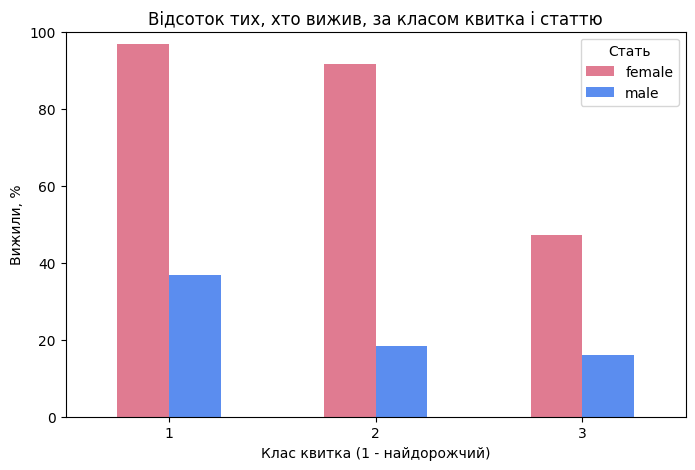

In [11]:
#Виживання за статтю і класом квитка
surv = titanic.groupby(["Pclass", "Sex"])["Survived"].mean().unstack() * 100

surv.plot(kind="bar", figsize=(8, 5), color=["#e07b91", "#5b8def"])
plt.title("Відсоток тих, хто вижив, за класом квитка і статтю")
plt.xlabel("Клас квитка (1 - найдорожчий)")
plt.ylabel("Вижили, %")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Стать")
plt.show()


Жінки виживали значно частіше за чоловіків: приблизно 74% проти 19%. Шанси також залежать від класу: у 1 класі вижило близько 63% пасажирів, у 3 класі лише близько 24%. Найкращі шанси мали жінки 1 класу (понад 95%), найгірші мали чоловіки 3 класу (близько 14%). Це узгоджується з правилом «жінки і діти першими» та з тим, що пасажири дорожчих класів мали кращий доступ до шлюпок.

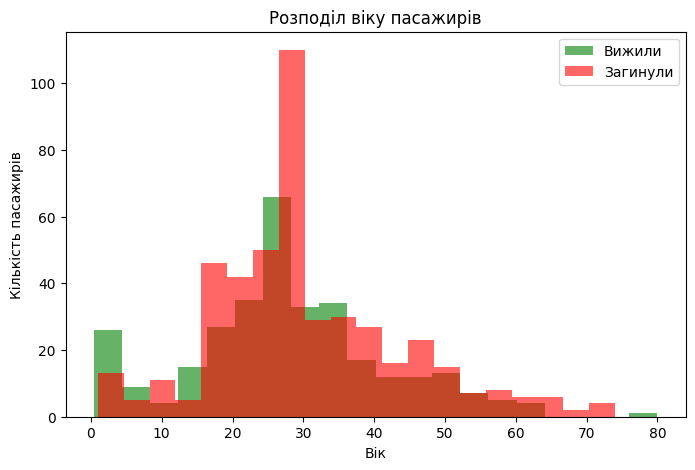

In [12]:
#Вік пасажирів: вижили чи ні
plt.figure(figsize=(8, 5))
plt.hist(titanic.loc[titanic["Survived"] == 1, "Age"], bins=20, alpha=0.6, label="Вижили", color="green")
plt.hist(titanic.loc[titanic["Survived"] == 0, "Age"], bins=20, alpha=0.6, label="Загинули", color="red")
plt.title("Розподіл віку пасажирів")
plt.xlabel("Вік")
plt.ylabel("Кількість пасажирів")
plt.legend()
plt.show()

Основна маса пасажирів мала 20–40 років. Середній вік тих, хто вижив, трохи менший за середній вік загиблих (приблизно 28 проти 30 років), тому вік впливав слабше, ніж стать і клас. Серед тих, хто вижив, помітна частка маленьких дітей. Високий стовпчик посередині частково утворений пропусками віку, які ми заповнили медіаною.

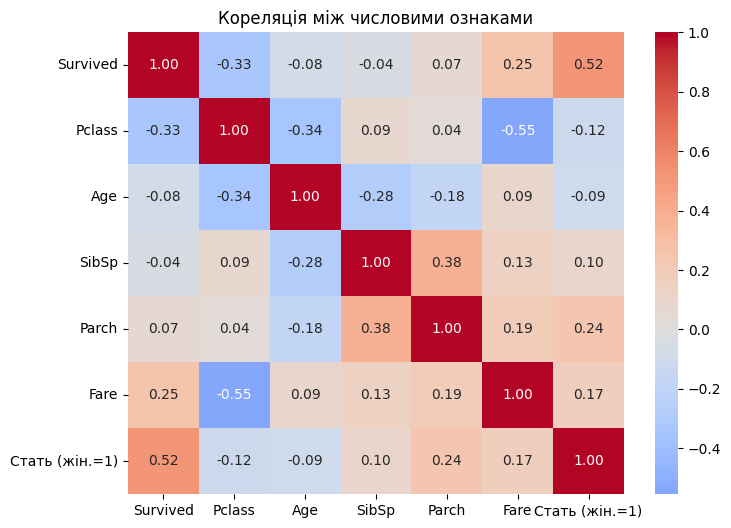

In [13]:
#Теплова карта кореляцій
corr_df = titanic.select_dtypes(include="number").copy()
corr_df["Стать (жін.=1)"] = (titanic["Sex"] == "female").astype(int)
corr = corr_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Кореляція між числовими ознаками")
plt.show()

Найсильніший зв'язок із виживанням мають жінки: кореляція близько 0,54. Далі йде клас квитка (приблизно −0,34): чим дорожчий клас, тобто менший номер, тим вищий шанс вижити. Ціна квитка пов'язана з виживанням слабше (приблизно 0,26), бо вона сама залежить від класу. Вік, кількість родичів на борту майже не впливають на результат.

Amazon

In [14]:

path = kagglehub.dataset_download("sootersaalu/amazon-top-50-bestselling-books-2009-2019")
print("Файли в датасеті:", os.listdir(path))
books = pd.read_csv(os.path.join(path, "bestsellers with categories.csv"))

100%|██████████| 14.5k/14.5k [00:00<00:00, 13.2MB/s]

Extracting files...
Файли в датасеті: ['bestsellers with categories.csv']


In [15]:
books_raw = books.copy()
books.head()

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


In [16]:
print("Рядків і стовпців:", books.shape)
books.info()

Рядків і стовпців: (550, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         550 non-null    object 
 1   Author       550 non-null    object 
 2   User Rating  550 non-null    float64
 3   Reviews      550 non-null    int64  
 4   Price        550 non-null    int64  
 5   Year         550 non-null    int64  
 6   Genre        550 non-null    object 
dtypes: float64(1), int64(3), object(3)
memory usage: 30.2+ KB


In [17]:
#Стовпці
books = books.rename(columns={
    "Name": "Назва", "Author": "Автор", "User Rating": "Рейтинг",
    "Reviews": "Відгуки", "Price": "Ціна", "Year": "Рік", "Genre": "Жанр",
})
print("Стовпці:", list(books.columns))

Стовпці: ['Назва', 'Автор', 'Рейтинг', 'Відгуки', 'Ціна', 'Рік', 'Жанр']


In [18]:
#Пропущені значення
print("Пропусків у кожному стовпці:")
print(books.isna().sum())

num_cols = ["Рейтинг", "Відгуки", "Ціна"]
books[num_cols] = books[num_cols].fillna(books[num_cols].mean())

print("\nПропусків після заповнення:", books.isna().sum().sum())
print("Безкоштовних книг (ціна 0):", (books["Ціна"] == 0).sum())

Пропусків у кожному стовпці:
Назва      0
Автор      0
Рейтинг    0
Відгуки    0
Ціна       0
Рік        0
Жанр       0
dtype: int64

Пропусків після заповнення: 0
Безкоштовних книг (ціна 0): 12


In [19]:
#Дублікати
print("Повних дублікатів:", books.duplicated().sum())
books = books.drop_duplicates()

print("Рядків у таблиці:", len(books))
print("Унікальних назв книг:", books["Назва"].nunique())

Повних дублікатів: 0
Рядків у таблиці: 550
Унікальних назв книг: 351


In [20]:
books.describe()

,Рейтинг,Відгуки,Ціна,Рік
count,550.000000,550.000000,550.000000,550.000000
mean,4.618364,11953.281818,13.100000,2014.000000
std,0.226980,11731.132017,10.842262,3.165156
min,3.300000,37.000000,0.000000,2009.000000
25%,4.500000,4058.000000,7.000000,2011.000000
50%,4.700000,8580.000000,11.000000,2014.000000
75%,4.800000,17253.250000,16.000000,2017.000000
max,4.900000,87841.000000,105.000000,2019.000000


In [21]:
#Загальний аналіз книг
print("Кількість книг за жанром:")
print(books["Жанр"].value_counts())

print("\nСередні показники за жанром:")
print(books.groupby("Жанр")[["Рейтинг", "Відгуки", "Ціна"]].mean().round(2))

print("\nТоп-5 книг за кількістю відгуків (за один рік):")
print(books.sort_values("Відгуки", ascending=False).head(5)[["Назва", "Автор", "Рік", "Відгуки"]])

print("\nКореляція між числовими ознаками:")
print(books[["Рейтинг", "Відгуки", "Ціна", "Рік"]].corr().round(2))

Кількість книг за жанром:
Жанр
Non Fiction    310
Fiction        240
Name: count, dtype: int64

Середні показники за жанром:
             Рейтинг   Відгуки   Ціна
Жанр                                 
Fiction         4.65  15683.79  10.85
Non Fiction     4.60   9065.15  14.84

Топ-5 книг за кількістю відгуків (за один рік):
                       Назва           Автор   Рік  Відгуки
534  Where the Crawdads Sing     Delia Owens  2019    87841
382    The Girl on the Train   Paula Hawkins  2015    79446
383    The Girl on the Train   Paula Hawkins  2016    79446
33                  Becoming  Michelle Obama  2019    61133
32                  Becoming  Michelle Obama  2018    61133

Кореляція між числовими ознаками:
         Рейтинг  Відгуки  Ціна   Рік
Рейтинг     1.00    -0.00 -0.13  0.24
Відгуки    -0.00     1.00 -0.11  0.26
Ціна       -0.13    -0.11  1.00 -0.15
Рік         0.24     0.26 -0.15  1.00


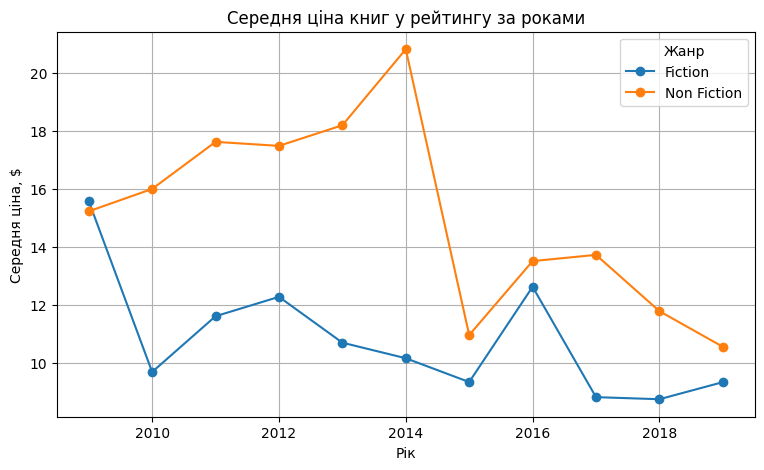

In [22]:
#Середня ціна за роками
price_year = books.pivot_table(index="Рік", columns="Жанр", values="Ціна", aggfunc="mean")

price_year.plot(marker="o", figsize=(9, 5))
plt.title("Середня ціна книг у рейтингу за роками")
plt.xlabel("Рік")
plt.ylabel("Середня ціна, $")
plt.grid(True)
plt.show()

З 2009 до 2019 року середня ціна книг у рейтингу загалом знизилась. Нехудожня література (Non Fiction) протягом усього періоду дорожча за художню (Fiction). Можливе пояснення: частка дешевших видань і м'яких палітурок у бестселерах зросла. Це припущення, а не доведений факт, бо в даних такого пояснення немає.

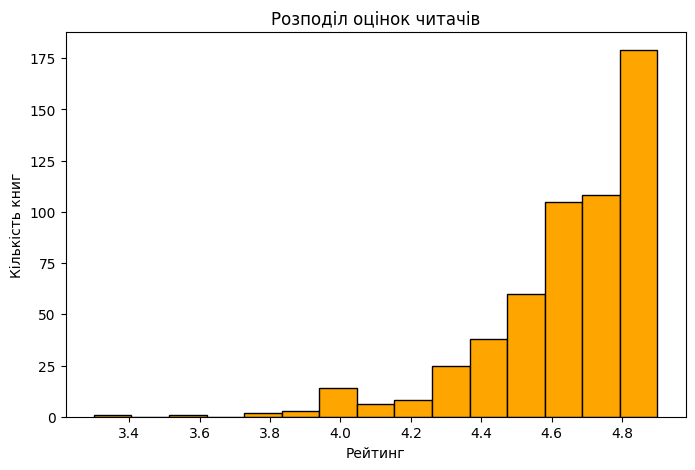

In [23]:
#Розподіл рейтингів
plt.figure(figsize=(8, 5))
plt.hist(books["Рейтинг"], bins=15, color="orange", edgecolor="black")
plt.title("Розподіл оцінок читачів")
plt.xlabel("Рейтинг")
plt.ylabel("Кількість книг")
plt.show()

Оцінки читачів лежать у межах від 3,3 до 4,9, а середня близько 4,6. Більшість книг має рейтинг 4,5 і вище, тож розподіл зміщений до високих значень. Це логічно: у список бестселерів потрапляють книги, які вже сподобались багатьом читачам.

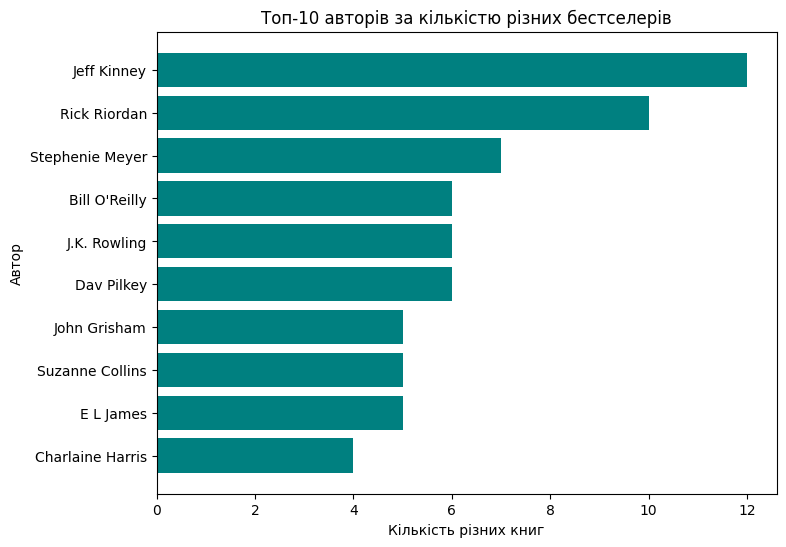

In [24]:
#Топ-10 авторів
top_authors = books.groupby("Автор")["Назва"].nunique().nlargest(10).sort_values()

plt.figure(figsize=(8, 6))
plt.barh(top_authors.index, top_authors.values, color="teal")
plt.title("Топ-10 авторів за кількістю різних бестселерів")
plt.xlabel("Кількість різних книг")
plt.ylabel("Автор")
plt.show()

Кілька авторів потрапляють у список по кілька разів, часто з різними книгами (наприклад, серії дитячих книг). Лідерів у списку небагато, а більшість авторів має по одній-дві книги. Тобто успіх у рейтингу не зосереджений в одного автора, але є невеликий набір постійних лідерів.